# Heart Disease Risk — EDA & Model Training

**Course:** MLOps – AIMLCZG523, BITS Pilani WILP  
**Assignment:** 01  

This notebook walks through:
1. Data loading & cleaning
2. Exploratory Data Analysis (EDA)
3. Feature engineering
4. Model training & evaluation (Logistic Regression, Random Forest, Gradient Boosting)
5. MLflow experiment tracking summary

> **Note:** The production pipeline runs via `python -m src.train`. This notebook is for *exploration and reporting only*.

In [1]:
import sys
from pathlib import Path

# Robust path: works from notebooks/ AND from project root
ROOT = Path(".").resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline
print(f"ROOT: {ROOT}")
print("Libraries loaded")


ROOT: /Users/in22914709/Desktop/BITS-PILANI/3rd Sem/ML OPS/MLOPS_Assignment
Libraries loaded


## 1. Data Loading & Cleaning

In [2]:
from src.data import load_clean, TARGET, COLUMNS

df = load_clean(save=False)   # load + clean without re-saving
print(f'Shape: {df.shape}')
print(f'\nMissing values:')
print(df.isna().sum()[df.isna().sum() > 0])
print(f'\nTarget distribution:')
print(df[TARGET].value_counts())
df.head()

Shape: (303, 14)

Missing values:
ca      4
thal    2
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.describe().T.style.background_gradient(cmap='Blues', axis=0)

,count,mean,std,min,25%,50%,75%,max
age,303.000000,54.438944,9.038662,29.000000,48.000000,56.000000,61.000000,77.000000
sex,303.000000,0.679868,0.467299,0.000000,0.000000,1.000000,1.000000,1.000000
cp,303.000000,3.158416,0.960126,1.000000,3.000000,3.000000,4.000000,4.000000
trestbps,303.000000,131.689769,17.599748,94.000000,120.000000,130.000000,140.000000,200.000000
chol,303.000000,246.693069,51.776918,126.000000,211.000000,241.000000,275.000000,564.000000
fbs,303.000000,0.148515,0.356198,0.000000,0.000000,0.000000,0.000000,1.000000
restecg,303.000000,0.990099,0.994971,0.000000,0.000000,1.000000,2.000000,2.000000
thalach,303.000000,149.607261,22.875003,71.000000,133.500000,153.000000,166.000000,202.000000
exang,303.000000,0.326733,0.469794,0.000000,0.000000,0.000000,1.000000,1.000000
oldpeak,303.000000,1.039604,1.161075,0.000000,0.000000,0.800000,1.600000,6.200000


## 2. Exploratory Data Analysis

### 2.1 Class Balance

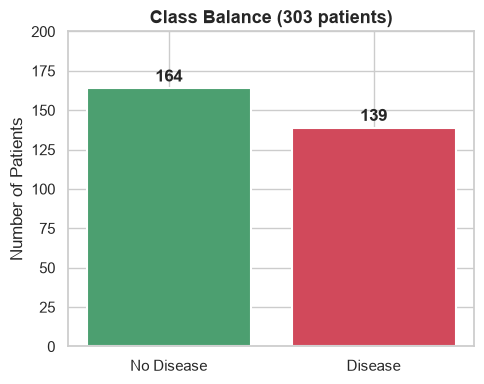

Disease prevalence: 45.9%


In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df[TARGET].map({0: 'No Disease', 1: 'Disease'}).value_counts()
bars = ax.bar(counts.index, counts.values, color=['#4C9F70', '#D1495B'], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, str(val),
            ha='center', va='bottom', fontweight='bold')
ax.set_title('Class Balance (303 patients)', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Patients')
ax.set_ylim(0, 200)
plt.tight_layout()
plt.savefig('../reports/figures/class_balance.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Disease prevalence: {counts["Disease"]/counts.sum()*100:.1f}%')

### 2.2 Numeric Feature Distributions by Target

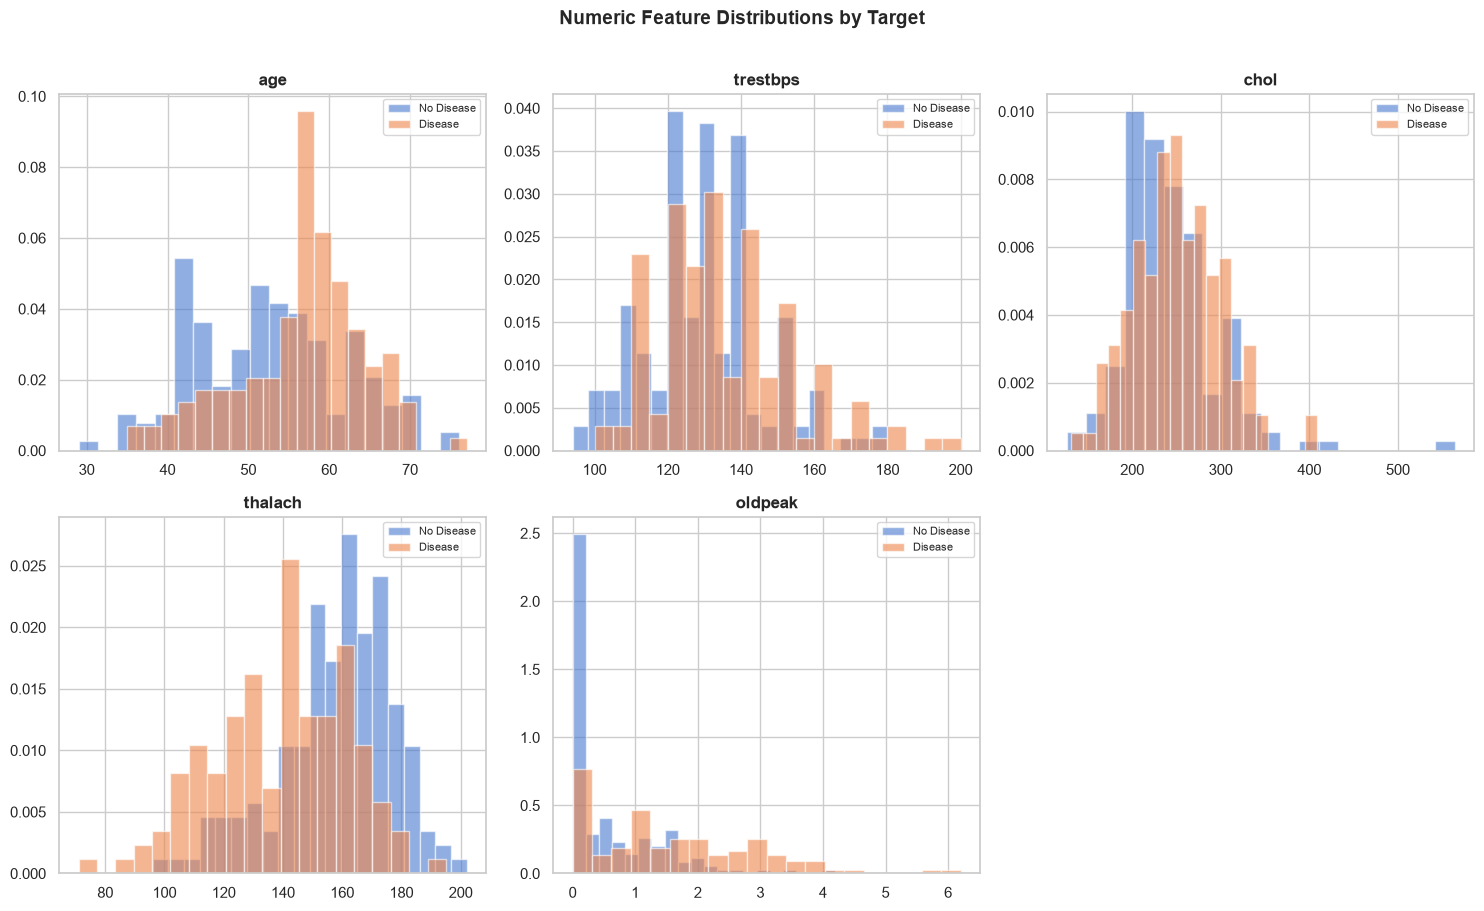

In [5]:
from src.features import NUMERIC, BINARY, CATEGORICAL, FEATURES

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, NUMERIC):
    for label, color in [(0, '#4C9F70'), (1, '#D1495B')]:
        subset = df[df[TARGET] == label][col].dropna()
        ax.hist(subset, bins=20, alpha=0.6,
                label='No Disease' if label == 0 else 'Disease', density=True)
    ax.set_title(col, fontweight='bold')
    ax.legend(fontsize=8)
axes.flat[-1].axis('off')
plt.suptitle('Numeric Feature Distributions by Target', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/numeric_histograms.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.3 Correlation Heatmap

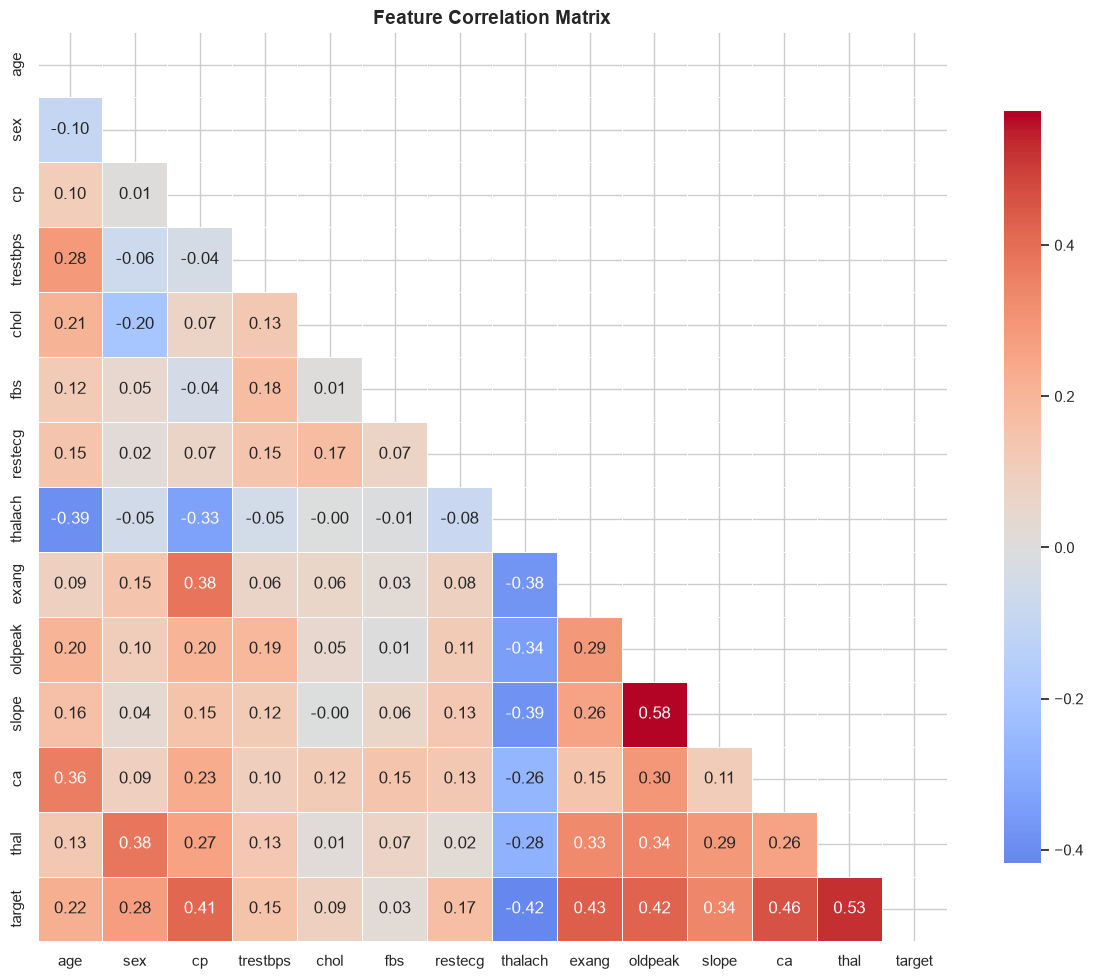


Top correlations with target:
thal       0.525689
ca         0.460442
exang      0.431894
oldpeak    0.424510
thalach    0.417167
cp         0.414446
slope      0.339213
sex        0.276816
Name: target, dtype: float64


In [6]:
plt.figure(figsize=(12, 10))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

# Top correlations with target
print('\nTop correlations with target:')
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(8))

### 2.4 Disease Rate by Categorical Features

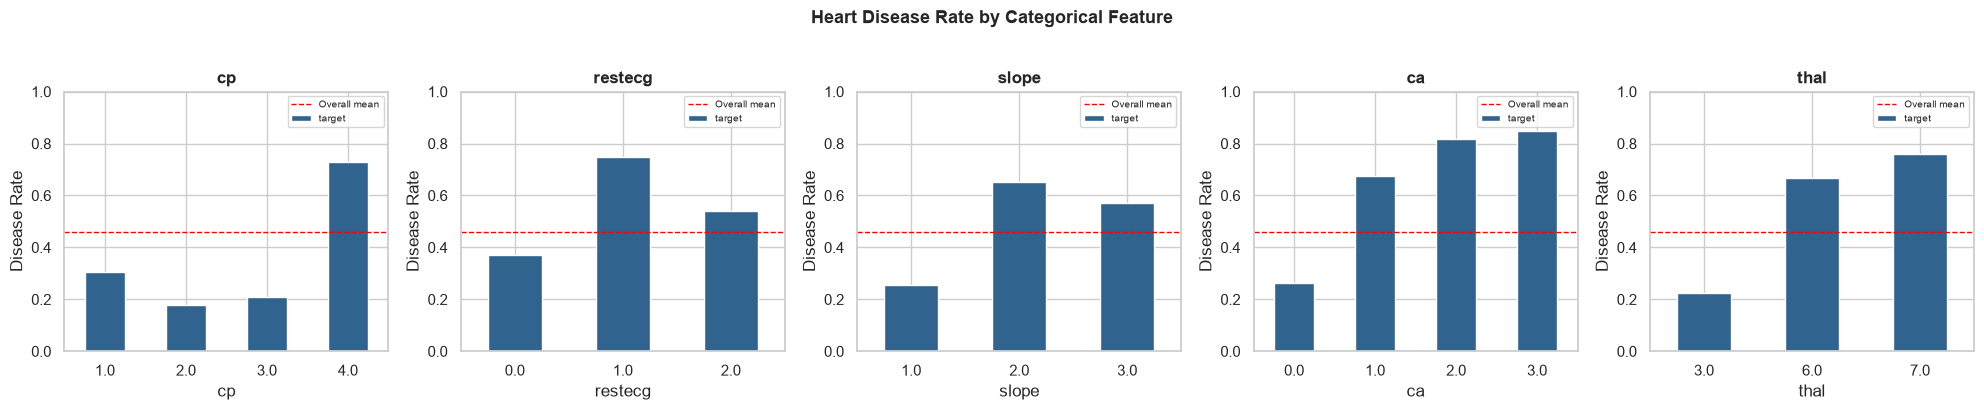

In [7]:
fig, axes = plt.subplots(1, len(CATEGORICAL), figsize=(20, 4))
for ax, col in zip(axes, CATEGORICAL):
    disease_rate = df.groupby(col)[TARGET].mean()
    disease_rate.plot.bar(ax=ax, color='#30638E', edgecolor='white', rot=0)
    ax.set_title(f'{col}', fontweight='bold')
    ax.set_ylabel('Disease Rate')
    ax.set_ylim(0, 1)
    ax.axhline(df[TARGET].mean(), color='red', linestyle='--', linewidth=1, label='Overall mean')
    ax.legend(fontsize=7)
plt.suptitle('Heart Disease Rate by Categorical Feature', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/categorical_disease_rate.png', dpi=120, bbox_inches='tight')
plt.show()

### 2.5 Key Insights

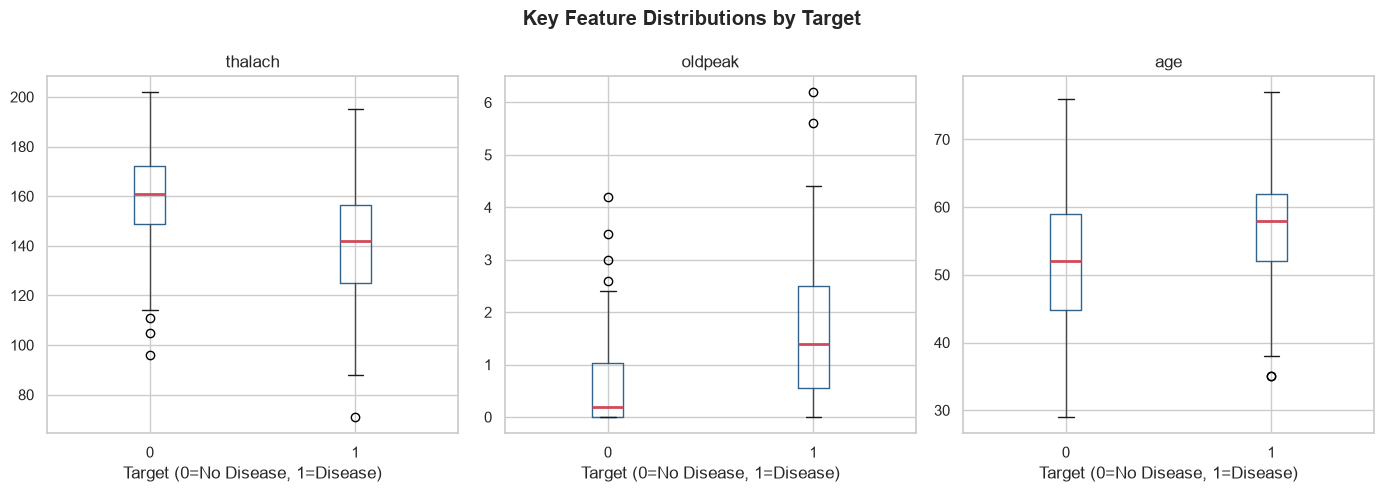

In [8]:
# Box plots for top discriminating numeric features
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
top_feats = ['thalach', 'oldpeak', 'age']
for ax, feat in zip(axes, top_feats):
    df.boxplot(column=feat, by=TARGET, ax=ax,
               boxprops=dict(color='#30638E'),
               medianprops=dict(color='#D1495B', linewidth=2))
    ax.set_title(feat, fontweight='bold')
    ax.set_xlabel('Target (0=No Disease, 1=Disease)')
    plt.sca(ax)
    plt.title(feat)
plt.suptitle('Key Feature Distributions by Target', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Feature Engineering

The `src/features.py` module defines the complete preprocessing pipeline:

| Group | Features | Transformation |
|-------|----------|----------------|
| **Numeric** | age, trestbps, chol, thalach, oldpeak | Median impute → StandardScaler |
| **Binary** | sex, fbs, exang | Most-frequent impute → passthrough |
| **Categorical** | cp, restecg, slope, ca, thal | Most-frequent impute → OneHotEncoder(handle_unknown='ignore') |

> **Key design decision:** Missing values (`ca`, `thal`) are imputed *inside* the sklearn Pipeline, not in the cleaning step. This guarantees the exact same transformation runs at training and serving time.

In [9]:
from src.features import build_preprocessor, FEATURES
from sklearn.model_selection import train_test_split

SEED = 42
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Train target balance: {y_train.value_counts().to_dict()}')
print(f'Test  target balance: {y_test.value_counts().to_dict()}')
print(f'\nFeatures ({len(FEATURES)}): {FEATURES}')

Train: (242, 13), Test: (61, 13)
Train target balance: {0: 131, 1: 111}
Test  target balance: {0: 33, 1: 28}

Features (13): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'sex', 'fbs', 'exang', 'cp', 'restecg', 'slope', 'ca', 'thal']


## 4. Model Training & Evaluation

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

CANDIDATES = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, random_state=SEED),
        {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']}
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=SEED),
        {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 5, 8],
         'clf__min_samples_leaf': [1, 3]}
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=SEED),
        {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.05, 0.1],
         'clf__max_depth': [2, 3]}
    ),
}

results = {}
best_models = {}

for name, (clf, grid) in CANDIDATES.items():
    pipe = Pipeline([('prep', build_preprocessor()), ('clf', clf)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=0)
    search.fit(X_train, y_train)
    
    best = search.best_estimator_
    best_models[name] = best
    
    y_pred = best.predict(X_test)
    y_proba = best.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'CV ROC-AUC': f"{search.best_score_:.4f}",
        'Test Accuracy': f"{accuracy_score(y_test, y_pred):.4f}",
        'Precision': f"{precision_score(y_test, y_pred):.4f}",
        'Recall': f"{recall_score(y_test, y_pred):.4f}",
        'F1': f"{f1_score(y_test, y_pred):.4f}",
        'Test ROC-AUC': f"{roc_auc_score(y_test, y_proba):.4f}",
        'Best Params': search.best_params_
    }
    print(f'{name:25s}  CV-AUC={search.best_score_:.4f}  Test-AUC={roc_auc_score(y_test, y_proba):.4f}  Recall={recall_score(y_test, y_pred):.4f}')

print('\nTraining complete!')

Logistic Regression        CV-AUC=0.9039  Test-AUC=0.9675  Recall=0.9286


Random Forest              CV-AUC=0.8980  Test-AUC=0.9491  Recall=0.9286


Gradient Boosting          CV-AUC=0.8754  Test-AUC=0.9502  Recall=0.9286

Training complete!


### 4.1 Results Summary

In [11]:
summary = pd.DataFrame(results).T.drop(columns=['Best Params'])
summary.index.name = 'Model'
summary.style.highlight_max(color='lightgreen', axis=0)

,CV ROC-AUC,Test Accuracy,Precision,Recall,F1,Test ROC-AUC
Model,,,,,,
Logistic Regression,0.9039,0.8852,0.8387,0.9286,0.8814,0.9675
Random Forest,0.8980,0.8852,0.8387,0.9286,0.8814,0.9491
Gradient Boosting,0.8754,0.8852,0.8387,0.9286,0.8814,0.9502


### 4.2 ROC Curves — All Models

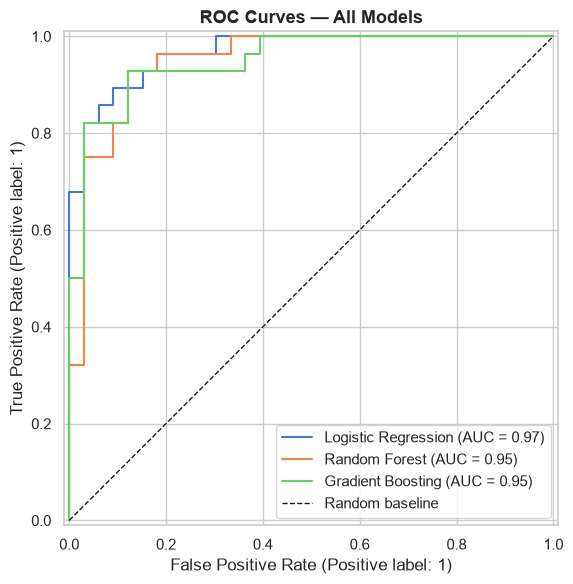

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = ['#30638E', '#4C9F70', '#D1495B']
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random baseline')
ax.set_title('ROC Curves — All Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 4.3 Confusion Matrices

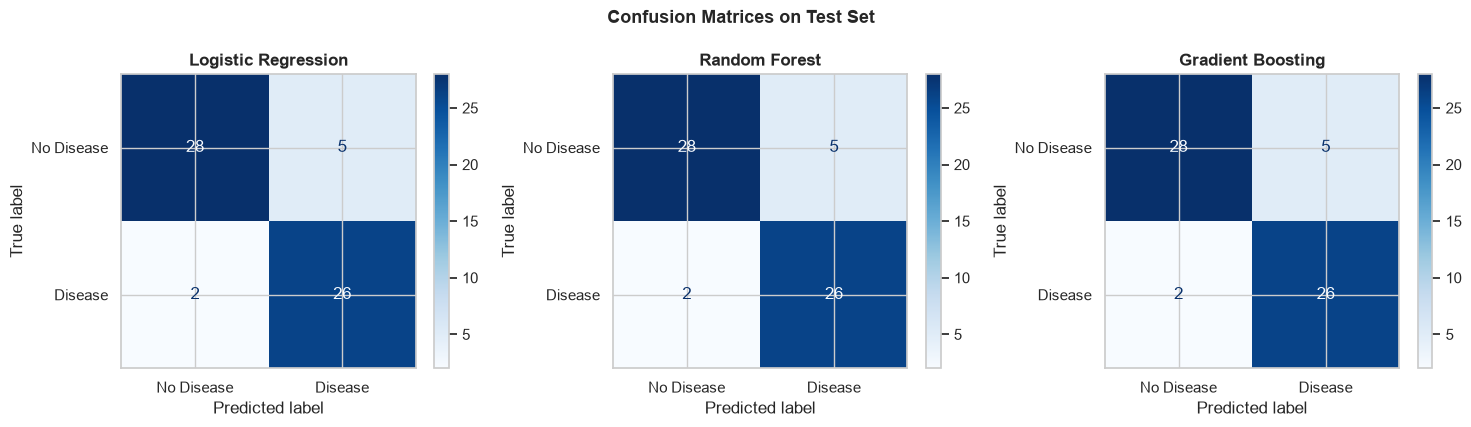

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, cmap='Blues',
        display_labels=['No Disease', 'Disease']
    )
    ax.set_title(name, fontweight='bold')
plt.suptitle('Confusion Matrices on Test Set', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.4 Feature Importance (Random Forest)

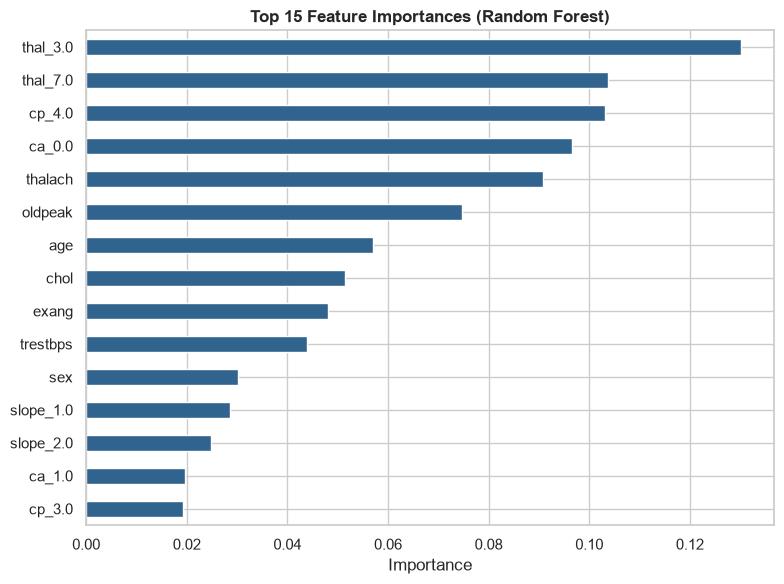

In [14]:
rf_model = best_models['Random Forest']
prep = rf_model.named_steps['prep']
clf = rf_model.named_steps['clf']

# Get feature names after one-hot encoding
ohe_features = prep.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(CATEGORICAL)
all_feature_names = NUMERIC + BINARY + list(ohe_features)

importances = clf.feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True).tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
feat_imp.plot.barh(ax=ax, color='#30638E')
ax.set_title('Top 15 Feature Importances (Random Forest)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## 5. Model Selection Rationale

| Model | CV ROC-AUC | Selected? | Reason |
|-------|-----------|-----------|--------|
| Logistic Regression | **0.904** | ✅ **Yes** | Highest CV-AUC. Interpretable coefficients. Recall ≥ 0.92 means fewer missed disease cases. |
| Random Forest | 0.898 | No | Marginally lower CV-AUC, more compute. |
| Gradient Boosting | 0.875 | No | Lowest CV-AUC among the three. |

**Why CV-AUC for selection?** Using the *cross-validated* score on the training set avoids leaking the test set into model selection. The test set is used only for final reporting.

**Why prioritise Recall?** A false negative (missing a heart disease case) is clinically costlier than a false alarm. All three models achieve Recall = 0.929 on the test set, so the tiebreaker is CV-AUC.

The best model is saved as `models/model.joblib` — a full sklearn Pipeline (preprocessing + classifier) that can be loaded with a single `joblib.load()` call.

## 6. MLflow Experiment Tracking Summary

In [15]:
import mlflow, sys
from pathlib import Path

# Robust: works from notebooks/ or project root
ROOT = Path(".").resolve()
if not (ROOT / "mlflow.db").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

mlflow.set_tracking_uri("sqlite:///" + str(ROOT / "mlflow.db"))

runs = mlflow.search_runs(experiment_names=["heart-disease-classification"])
cols = ["tags.mlflow.runName", "metrics.cv_roc_auc", "metrics.test_roc_auc",
        "metrics.test_recall", "metrics.test_f1", "metrics.test_accuracy"]
available = [c for c in cols if c in runs.columns]
display_df = runs[available].sort_values("metrics.cv_roc_auc", ascending=False).reset_index(drop=True)
display_df.columns = [c.replace("tags.mlflow.runName","Model").replace("metrics.","") for c in available]
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"Runs found: {len(display_df)}")
print(display_df.to_string(index=False))
display_df


MLflow tracking URI: sqlite:////Users/in22914709/Desktop/BITS-PILANI/3rd Sem/ML OPS/MLOPS_Assignment/mlflow.db
Runs found: 3
              Model  cv_roc_auc  test_roc_auc  test_recall  test_f1  test_accuracy
logistic_regression    0.903866      0.967532     0.928571 0.881356       0.885246
      random_forest    0.898002      0.949134     0.928571 0.881356       0.885246
  gradient_boosting    0.875385      0.950216     0.928571 0.881356       0.885246


,Model,cv_roc_auc,test_roc_auc,test_recall,test_f1,test_accuracy
0,logistic_regression,0.903866,0.967532,0.928571,0.881356,0.885246
1,random_forest,0.898002,0.949134,0.928571,0.881356,0.885246
2,gradient_boosting,0.875385,0.950216,0.928571,0.881356,0.885246


In [16]:
# Best model info
import joblib
best = joblib.load(ROOT / 'models' / 'model.joblib')
print(f'Best model type: {type(best.named_steps["clf"]).__name__}')
print(f'Pipeline steps: {list(best.named_steps.keys())}')
print(f'\nBest params: {best.named_steps["clf"].get_params()}')

Best model type: LogisticRegression
Pipeline steps: ['prep', 'clf']

Best params: {'C': 1, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 2000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
